# Cellpose3: how do degraded images affect the segmentation?

Phase 1: we treat Cellpose3 as a black box. We take images with ground truth masks, degrade them with 8 different augmentations and check what the model gets wrong.

Two pipelines are compared:
- **cyto3**: the segmentation model directly on the degraded image
- **denoise+cyto3**: the image is first restored with `denoise_cyto3` and then segmented with `cyto3`

In [3]:
import os
import glob
import gzip
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from PIL import Image
from scipy import ndimage as ndi
import torch
from cellpose import models, denoise, utils

torch.backends.mkldnn.enabled = False  # the model crashed on some image sizes without this

N_IMAGES = 30 
MIN_CELLS = 5   
SEED = 0

## 1. Dataset



In [4]:
def to_uint8(x):
    lo, hi = np.percentile(x, [0.5, 99.8])
    x = (x - lo) / max(hi - lo, 1e-6)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)


def relabel(masks):
    _, inverse = np.unique(masks, return_inverse=True)
    return inverse.reshape(masks.shape).astype(np.int32)


def random_order(n):
    return np.random.default_rng(SEED).permutation(n)


def make_sample(dataset, i, img, gt, channels, diam=None):
    gt = relabel(gt)
    if diam is None:
        diam = utils.diameters(gt)[0]
    return {"dataset": dataset, "id": int(i), "img": img, "gt": gt, "channels": channels, "diam": float(diam)}


def load_cellpose(path="data/cellpose/test_poisson.npz"):
    if not os.path.exists(path):
        print("Cellpose dataset not found:", path)
        return []
    d = np.load(path, allow_pickle=True)["arr_0"].item()
    samples = []
    for i in random_order(len(d["test_data"])):
        gt = d["masks_true"][i]
        if gt.max() < MIN_CELLS:
            continue
        gray = to_uint8(d["test_data"][i][0])
        img = np.stack([gray, gray, gray], axis=-1)
        samples.append(make_sample("cellpose", i, img, gt, [0, 0], d["diam_test"][i]))
        if len(samples) == N_IMAGES:
            break
    return samples





data = {"cellpose": load_cellpose()}
data = {name: samples for name, samples in data.items() if samples}

for name, samples in data.items():
    n_cells = sum(s["gt"].max() for s in samples)
    diams = [s["diam"] for s in samples]
    print(f"{name}: {len(samples)} images, {n_cells} cells, diameter {np.min(diams):.0f}-{np.max(diams):.0f} px")

cellpose: 30 images, 2479 cells, diameter 16-82 px


## 2. Augmentations


| augmentation | what it does |
|---|---|
| noise | gaussian noise, sigma 10 / 25 / 50 (on a 0-255 scale) |
| blur | gaussian blur, sigma 1 / 2 / 4 px |
| overexposed | brightness x2, bright pixels get clipped |
| invert | 255 - image |
| red | the whole signal is moved into the red channel |
| hue | hue shift by 180 degrees (e.g. a different staining color) |
| rotate | rotation by 90 degrees |
| mirror | flip left-right |


In [5]:
def augment(img, name, level=None, seed=0):
    x = img.astype(float)
    if name == "original":
        out = x
    elif name == "noise":
        rng = np.random.default_rng(seed)
        out = x + rng.normal(0, level, x.shape[:2] + (1,)) 
    elif name == "blur":
        out = ndi.gaussian_filter(x, sigma=(level, level, 0))
    elif name == "overexposed":
        out = x * level
    elif name == "invert":
        out = 255 - x
    elif name == "red":
        out = np.zeros_like(x)
        out[..., 0] = x.max(axis=-1)
    elif name == "hue":
        hsv = np.array(Image.fromarray(img).convert("HSV")).astype(int)
        hsv[..., 0] = (hsv[..., 0] + round(level / 360 * 256)) % 256
        out = np.array(Image.fromarray(hsv.astype(np.uint8), "HSV").convert("RGB")).astype(float)
    elif name == "rotate":
        out = np.rot90(x, k=level // 90)
    elif name == "mirror":
        out = np.fliplr(x)
    else:
        raise ValueError(name)
    return np.clip(out, 0, 255).astype(np.uint8)


def undo_geometry(arr, name, level=None):
    if name == "rotate":
        return np.rot90(arr, k=-(level // 90))
    if name == "mirror":
        return np.fliplr(arr)
    return arr


CONDITIONS = [
    ("original", None),
    ("noise", 10), ("noise", 25), ("noise", 50),
    ("blur", 1), ("blur", 2), ("blur", 4),
    ("overexposed", 2),
    ("invert", None),
    ("red", None),
    ("hue", 180),
    ("rotate", 90),
    ("mirror", None),
]
LABELS = [name if level is None else f"{name} {level}" for name, level in CONDITIONS]
CONDITION = dict(zip(LABELS, CONDITIONS))
print(len(CONDITIONS), "conditions")

13 conditions


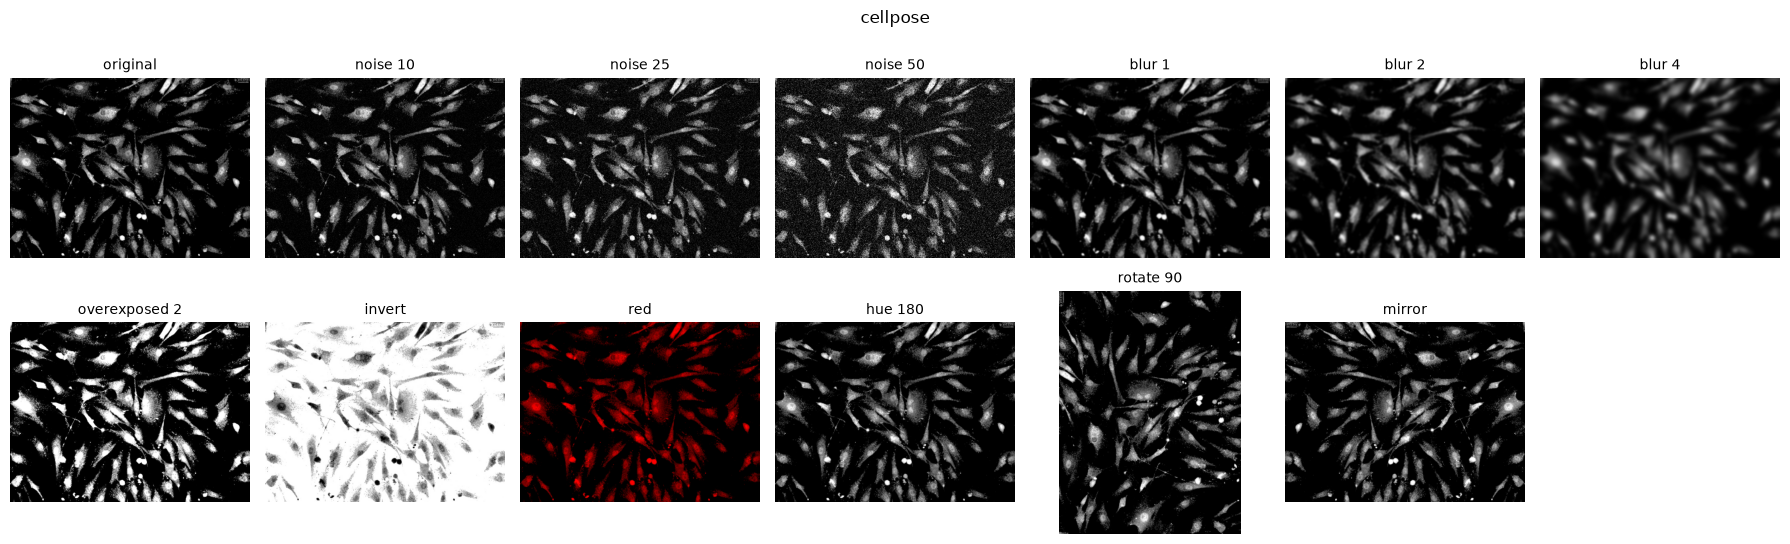

In [6]:
for name, samples in data.items():
    img = samples[0]["img"]
    fig, axes = plt.subplots(2, 7, figsize=(18, 5.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, label in zip(axes.ravel(), LABELS):
        ax.imshow(augment(img, *CONDITION[label]))
        ax.set_title(label, fontsize=10)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## 3. Run the models



In [7]:
seg_model = models.CellposeModel(gpu=False, model_type="cyto3")
dn_model = denoise.CellposeDenoiseModel(gpu=False, model_type="cyto3", restore_type="denoise_cyto3")
PIPELINES = ["cyto3", "denoise+cyto3"]


def segment(s, img, pipeline):
    if pipeline == "cyto3":
        masks, _, _ = seg_model.eval(img, diameter=s["diam"], channels=s["channels"])
    else:
        masks, _, _, _ = dn_model.eval(img, diameter=s["diam"], channels=s["channels"])
    return masks.astype(np.uint16)


def run_image(s):
    path = f"cache/{s['dataset']}_{s['id']}.pkl.gz"
    preds = {}
    if os.path.exists(path):
        with gzip.open(path, "rb") as f:
            preds = pickle.load(f)

    changed = False
    for label in LABELS:
        name, level = CONDITION[label]
        img = augment(s["img"], name, level, seed=s["id"])
        for pipeline in PIPELINES:
            if (label, pipeline) in preds:
                continue
            masks = segment(s, img, pipeline)
            preds[(label, pipeline)] = undo_geometry(masks, name, level)
            changed = True

    if changed:
        with gzip.open(path, "wb") as f:
            pickle.dump(preds, f)
    return preds


os.makedirs("cache", exist_ok=True)
for name, samples in data.items():
    t0 = time.time()
    for k, s in enumerate(samples):
        s["pred"] = run_image(s)
        print(f"{name}: {k + 1}/{len(samples)} done ({time.time() - t0:.0f}s)")

cellpose: 1/30 done (0s)
cellpose: 2/30 done (1s)
cellpose: 3/30 done (1s)
cellpose: 4/30 done (1s)
cellpose: 5/30 done (1s)
cellpose: 6/30 done (2s)
cellpose: 7/30 done (2s)
cellpose: 8/30 done (2s)
cellpose: 9/30 done (3s)
cellpose: 10/30 done (3s)
cellpose: 11/30 done (3s)
cellpose: 12/30 done (3s)
cellpose: 13/30 done (4s)
cellpose: 14/30 done (4s)
cellpose: 15/30 done (4s)
cellpose: 16/30 done (5s)
cellpose: 17/30 done (5s)
cellpose: 18/30 done (5s)
cellpose: 19/30 done (6s)
cellpose: 20/30 done (6s)
cellpose: 21/30 done (6s)
cellpose: 22/30 done (7s)
cellpose: 23/30 done (7s)
cellpose: 24/30 done (7s)
cellpose: 25/30 done (7s)
cellpose: 26/30 done (7s)
cellpose: 27/30 done (8s)
cellpose: 28/30 done (8s)
cellpose: 29/30 done (8s)
cellpose: 30/30 done (9s)


## 4. Compare with the ground truth

Every ground truth cell gets one label:
- **matched**: a predicted cell overlaps it with IoU > 0.5
- **merged**: one predicted cell contains at least half of this cell and half of another cell
- **split**: two or more predicted cells lie mostly (>= 50 %) inside this cell
- **missed**: none of the above 


In [8]:
STATUS_COLORS = {"matched": "tab:green", "merged": "tab:orange", "split": "tab:purple", "missed": "tab:red"}


def classify_cells(gt, pred):
    n_gt, n_pred = gt.max(), pred.max()
    pred = pred.astype(np.int64)
    overlap = np.bincount(gt.ravel() * (n_pred + 1) + pred.ravel(), minlength=(n_gt + 1) * (n_pred + 1))
    overlap = overlap.reshape(n_gt + 1, n_pred + 1)
    area_gt = overlap[1:].sum(axis=1)
    overlap = overlap[1:, 1:]  # without background
    area_pred = np.bincount(pred.ravel(), minlength=n_pred + 1)[1:]

    iou = overlap / np.maximum(area_gt[:, None] + area_pred[None, :] - overlap, 1)
    covers = overlap >= 0.5 * area_gt[:, None]    # pred contains half of the gt cell
    inside = overlap >= 0.5 * area_pred[None, :]  # pred lies mostly in the gt cell

    matched = (iou > 0.5).any(axis=1)
    merged = (covers & (covers.sum(axis=0) >= 2)).any(axis=1)
    split = inside.sum(axis=1) >= 2

    status = np.full(n_gt, "missed", dtype=object)
    status[split] = "split"
    status[merged] = "merged"
    status[matched] = "matched"

    no_match = (iou <= 0.5).all(axis=0)
    false_pos = no_match & ~inside.any(axis=0) & (covers.sum(axis=0) < 2)
    return status, int(false_pos.sum())


rows, cell_rows = [], []
for name, samples in data.items():
    for s in samples:
        gt = s["gt"]
        area = np.bincount(gt.ravel())[1:]
        size_q = pd.qcut(pd.Series(area).rank(method="first"), 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
        for label in LABELS:
            aug, level = CONDITION[label]
            for pipeline in PIPELINES:
                pred = s["pred"][(label, pipeline)]
                status, n_fp = classify_cells(gt, pred)
                n_gt, n_pred = gt.max(), pred.max()
                n_match = (status == "matched").sum()
                row = {"dataset": name, "id": s["id"], "condition": label, "augmentation": aug,
                       "level": level, "pipeline": pipeline, "n_gt": n_gt, "n_pred": n_pred,
                       "AP50": n_match / (n_gt + n_pred - n_match),
                       "count_ratio": n_pred / n_gt, "false_pos": n_fp / n_gt}
                for st in STATUS_COLORS:
                    row[st] = (status == st).mean()
                rows.append(row)
                cell_rows.append(pd.DataFrame({"dataset": name, "id": s["id"], "condition": label,
                                               "pipeline": pipeline, "area": area, "size_q": size_q,
                                               "status": status}))

res = pd.DataFrame(rows)
cells = pd.concat(cell_rows, ignore_index=True)
print(len(res), "image results,", len(cells), "cell results")
res.groupby(["dataset", "pipeline"])[["AP50"] + list(STATUS_COLORS)].mean().round(3)

780 image results, 64454 cell results


AP50  matched  merged  split  missed
dataset  pipeline                                            
cellpose cyto3          0.719    0.771   0.057  0.007   0.165
         denoise+cyto3  0.747    0.797   0.062  0.006   0.136

## 5. Results

### Overview: AP@0.5 and number of predicted cells
A count ratio below 1 means the model finds fewer cells than there are (merging or missing), above 1 means more (splitting or false positives).

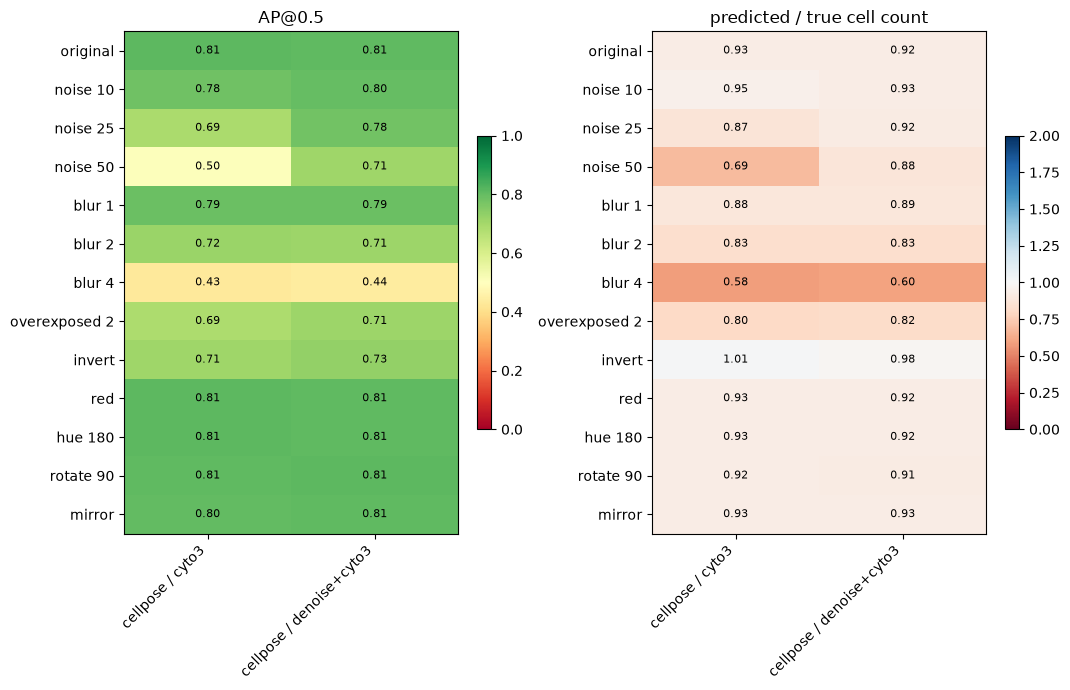

In [9]:
def heatmap(table, title, ax, vmin=0, vmax=1, cmap="RdYlGn"):
    im = ax.imshow(table.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=45, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.04)


n_cols = res.groupby(["dataset", "pipeline"]).ngroups
fig, axes = plt.subplots(1, 2, figsize=(2 * (1.2 * n_cols + 3), 7))
for ax, (col, title, vmin, vmax, cmap) in zip(axes, [("AP50", "AP@0.5", 0, 1, "RdYlGn"),
                                                    ("count_ratio", "predicted / true cell count", 0, 2, "RdBu")]):
    t = res.pivot_table(index="condition", columns=["dataset", "pipeline"], values=col, aggfunc="mean")
    t = t.reindex(LABELS)
    t.columns = [f"{d} / {p}" for d, p in t.columns]
    heatmap(t, title, ax, vmin, vmax, cmap)
plt.tight_layout()
plt.show()

### What kind of errors?
Share of ground truth cells that are matched, merged, split or missed.

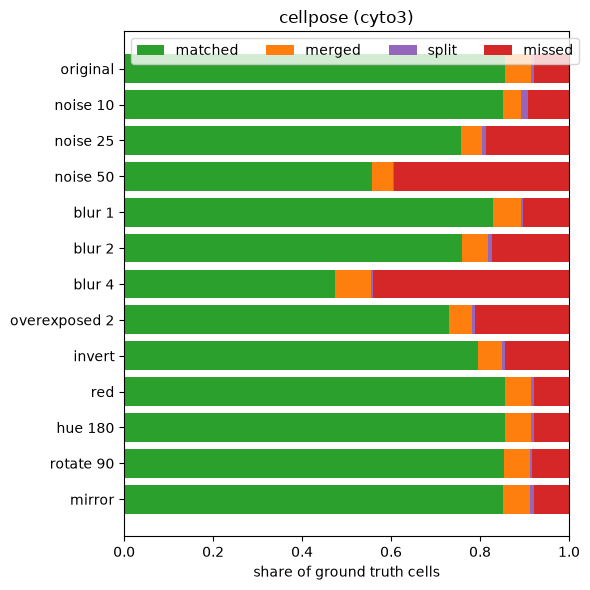

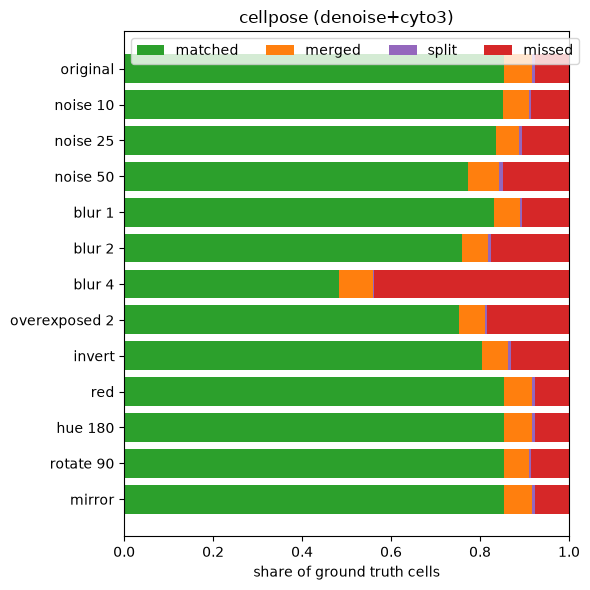

In [10]:
def error_bars(pipeline):
    names = list(data)
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 6), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], names):
        sub = res[(res["dataset"] == name) & (res["pipeline"] == pipeline)]
        t = sub.groupby("condition")[list(STATUS_COLORS)].mean().reindex(LABELS)
        left = np.zeros(len(t))
        for st, color in STATUS_COLORS.items():
            ax.barh(t.index, t[st], left=left, color=color, label=st)
            left += t[st].values
        ax.set_xlim(0, 1)
        ax.set_xlabel("share of ground truth cells")
        ax.set_title(f"{name} ({pipeline})")
    axes[0, 0].invert_yaxis()
    axes[0, 0].legend(loc="upper left", ncol=4)
    plt.tight_layout()
    plt.show()


error_bars("cyto3")
error_bars("denoise+cyto3")

### Which cells get lost?
Share of matched cells per cell size (quartiles inside each image), cyto3 only.

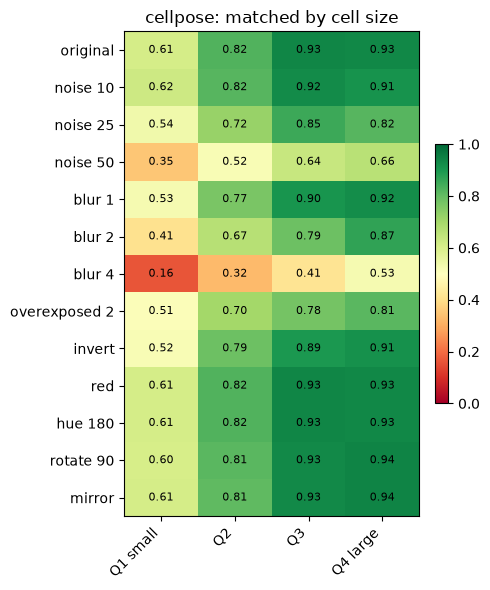

In [11]:
names = list(data)
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 6), squeeze=False)
for ax, name in zip(axes[0], names):
    sub = cells[(cells["dataset"] == name) & (cells["pipeline"] == "cyto3")].copy()
    sub["found"] = sub["status"] == "matched"
    t = sub.pivot_table(index="condition", columns="size_q", values="found", aggfunc="mean", observed=False)
    heatmap(t.reindex(LABELS), f"{name}: matched by cell size", ax)
plt.tight_layout()
plt.show()

### Conclusion

We applied 8 different augmentations to the test data, with some variants, for a total of 12 different augmentations.
We were interested in whether altering the input data affects cell detection.
The model performed impressively well on most augmentations. Rotations had basically zero effect on cell prediction, as did coloring the image red.
The model performed worst when we added noise and blurred the images.
Denoising before segmentation helps strongly against noise (AP@0.5 at noise 50 rises from 0.50 to 0.71) but does not help against blur (blur 4: 0.43 vs. 0.44). On all other augmentations both pipelines perform about the same.
The dominant source of error was that the model just missed cells; some cells got merged, and almost no cells got wrongly split.
Taking cell size into account, we see that the error is large for the smallest 25% of cells: with *blur 4*, the matched share is only 0.16, while the original can find a share of 0.61.